# Universal noise GAN

**Goal:** Instead of using the fixed sinusoidal trigger (`1xs`) from the FLIP paper, we train a GAN to generate a universal noise pattern that can be used as a new trigger.

Unlike the image-specific approach, where the generator produces different noise for each image, here it generates one single perturbation δ, applied to every truck image. The noise has size 3×32×32 and is limited to ‖δ‖∞ ≤ ε, with ε = 6/255 to match the amplitude of the original sinusoidal trigger.

### How it works

- **Generator:** produces the universal noise δ, which is added to all truck images. The bound ‖δ‖∞ ≤ ε is enforced directly in the architecture (ε · tanh).
- **Discriminator:** tries to distinguish clean trucks from trucks with the generated noise.
- **Surrogate classifier:** a ResNet-32 trained on clean CIFAR-10 and then frozen, which helps the generator learn noise that makes trucks more likely to be classified as *deer*.

### Generator Loss

The generator combines two objectives:

$$
L_G = \lambda_{\text{adv}} L_{\text{adv}} + \lambda_{\text{tgt}} L_{\text{tgt}}
$$

- **Adversarial loss:** makes the modified images difficult for the discriminator to distinguish from clean ones.
- **Target loss:** encourages the classifier to predict *deer* instead of *truck*.

No extra penalty on the size of the noise is needed, since the ε bound already keeps the perturbation small.

In [5]:
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import numpy as np
import os

from modules.GAN_noise_generation.universal import UniversalNoiseGenerator, RealismDiscriminator, normalize_cifar
from modules.base_utils.util import load_model

# Load the dataset

In [6]:
# image tensors have values in the range [0, 1]
transform = transforms.ToTensor()

raw_train = datasets.CIFAR10("./data/data_cifar10", train=True, download=False)
dataset = datasets.CIFAR10("./data/data_cifar10", train=True, download=False, transform=transform)

source_class = 'truck'
target_class = 'deer'
source_index = raw_train.class_to_idx[source_class]
target_index = raw_train.class_to_idx[target_class]

trucks = [img for _, (img, label) in enumerate(dataset) if label == source_index]
trucks_tensor = torch.stack(trucks)
truck_loader = DataLoader(trucks_tensor, batch_size=256, shuffle=True, num_workers=4, drop_last=True)

print(trucks_tensor.shape)

torch.Size([5000, 3, 32, 32])


In [7]:
generator = UniversalNoiseGenerator()
n_params = sum(p.numel() for p in generator.parameters() if p.requires_grad)
n_params

1072323

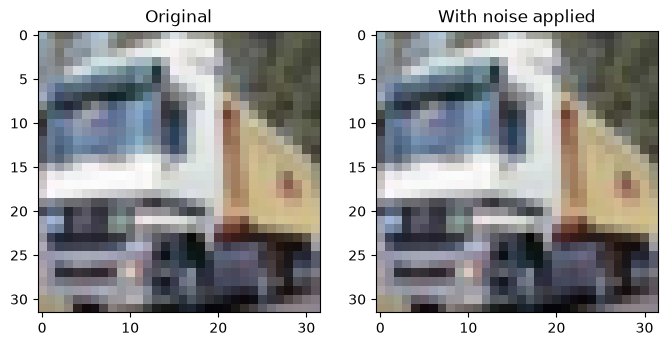

In [8]:
# noise of the untrained generator, applied to one truck
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

img = trucks_tensor[0]
noise = generator().detach().squeeze(0)        # the same noise for every image

axes[0].imshow(img.permute(1, 2, 0))
axes[0].set_title('Original')

axes[1].imshow((img + noise).clamp(0, 1).permute(1, 2, 0))
axes[1].set_title('With noise applied')

plt.show()

In [9]:
EPS = 6 / 255          # max change per pixel (same as the sinusoidal trigger of the paper)
LAMBDA_ADV = 1         # weight of "fool the discriminator"
LAMBDA_TARGET = 1      # weight of "push the truck towards deer" (0 = realism only)
LEARNING_RATE = 2e-4
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
NUM_EPOCHS = 30

# Surrogate classifier

A ResNet-32 trained on clean CIFAR-10 (the same architecture as the expert in FLIP). It is trained once,
saved, and then frozen: during the GAN training it only tells the generator in which direction "deer" is.

In [10]:
surrogate_path = "noise_generator/surrogate_r32p_clean.pth"
surrogate = load_model("r32p", 10)

if os.path.exists(surrogate_path):
    surrogate.load_state_dict(torch.load(surrogate_path, map_location=DEVICE))
else:
    train_transform = transforms.Compose([
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor()
    ])
    clean_dataset = datasets.CIFAR10("./data/data_cifar10", train=True, download=False, transform=train_transform)
    clean_loader = DataLoader(clean_dataset, batch_size=256, shuffle=True, num_workers=4)
    opt_surrogate = optim.SGD(surrogate.parameters(), lr=0.1, momentum=0.9, nesterov=True, weight_decay=2e-4)

    for epoch in range(30):
        surrogate.train()
        for x, y in clean_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            loss = F.cross_entropy(surrogate(normalize_cifar(x)), y)
            opt_surrogate.zero_grad()
            loss.backward()
            opt_surrogate.step()
        print(f"Surrogate epoch [{epoch+1}/30] | Loss: {loss.item():.4f}")

    os.makedirs("noise_generator", exist_ok=True)
    torch.save(surrogate.state_dict(), surrogate_path)

# frozen: it is never updated during the GAN training
surrogate.eval()
for p in surrogate.parameters():
    p.requires_grad = False

Surrogate epoch [1/30] | Loss: 1.0269
Surrogate epoch [2/30] | Loss: 0.7988
Surrogate epoch [3/30] | Loss: 0.8714
Surrogate epoch [4/30] | Loss: 0.6786
Surrogate epoch [5/30] | Loss: 0.6746
Surrogate epoch [6/30] | Loss: 0.6004
Surrogate epoch [7/30] | Loss: 0.4882
Surrogate epoch [8/30] | Loss: 0.3762
Surrogate epoch [9/30] | Loss: 0.4447
Surrogate epoch [10/30] | Loss: 0.3370
Surrogate epoch [11/30] | Loss: 0.5146
Surrogate epoch [12/30] | Loss: 0.3497
Surrogate epoch [13/30] | Loss: 0.3608
Surrogate epoch [14/30] | Loss: 0.3490
Surrogate epoch [15/30] | Loss: 0.5018
Surrogate epoch [16/30] | Loss: 0.3214
Surrogate epoch [17/30] | Loss: 0.3406
Surrogate epoch [18/30] | Loss: 0.4548
Surrogate epoch [19/30] | Loss: 0.3700
Surrogate epoch [20/30] | Loss: 0.3176
Surrogate epoch [21/30] | Loss: 0.3654
Surrogate epoch [22/30] | Loss: 0.1810
Surrogate epoch [23/30] | Loss: 0.2959
Surrogate epoch [24/30] | Loss: 0.3609
Surrogate epoch [25/30] | Loss: 0.2830
Surrogate epoch [26/30] | Loss: 0.

# Training

At each batch:
1. **Discriminator**: learns to separate clean trucks from trucks + noise.
2. **Generator**: changes the noise so that (a) the discriminator thinks it is clean and (b) the surrogate says *deer*.

In [11]:
generator = UniversalNoiseGenerator(eps=EPS).to(DEVICE)
discriminator = RealismDiscriminator().to(DEVICE)

opt_disc = optim.Adam(discriminator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))
opt_gen = optim.Adam(generator.parameters(), lr=LEARNING_RATE, betas=(0.5, 0.999))

BCE = nn.BCEWithLogitsLoss()
CE = nn.CrossEntropyLoss()

for epoch in range(NUM_EPOCHS):
    generator.train()

    for x in truck_loader:
        x = x.to(DEVICE)
        target = torch.full((x.shape[0],), target_index, device=DEVICE)

        # the same noise is added to every image of the batch
        noise = generator()
        x_noisy = (x + noise).clamp(0, 1)

        # 1. Discriminator Training
        preds_real = discriminator(x)                    # clean trucks
        loss_d_real = BCE(preds_real, torch.ones_like(preds_real))

        preds_fake = discriminator(x_noisy.detach())     # trucks + noise
        loss_d_fake = BCE(preds_fake, torch.zeros_like(preds_fake))

        loss_disc = (loss_d_real + loss_d_fake) / 2
        discriminator.zero_grad()
        loss_disc.backward()
        opt_disc.step()

        # 2. Generator Training
        # (a) the noise must stay invisible: fool the discriminator
        preds_fake_for_gen = discriminator(x_noisy)
        loss_gen_adv = BCE(preds_fake_for_gen, torch.ones_like(preds_fake_for_gen))

        # (b) the noise must carry a signal: truck + noise should look like a deer
        preds_class = surrogate(normalize_cifar(x_noisy))
        loss_gen_target = CE(preds_class, target)

        loss_gen = LAMBDA_ADV * loss_gen_adv + LAMBDA_TARGET * loss_gen_target
        generator.zero_grad()
        loss_gen.backward()
        opt_gen.step()

    truck_to_deer = (preds_class.argmax(1) == target_index).float().mean().item()
    print(f"Epoch [{epoch+1}/{NUM_EPOCHS}] | Loss D: {loss_disc.item():.4f}, Loss G: {loss_gen.item():.4f} "
          f"| Truck->deer: {truck_to_deer:.2f}")

Epoch [1/30] | Loss D: 1.0278, Loss G: 5.2848 | Truck->deer: 0.04
Epoch [2/30] | Loss D: 0.5955, Loss G: 4.4573 | Truck->deer: 0.09
Epoch [3/30] | Loss D: 0.1018, Loss G: 7.4917 | Truck->deer: 0.14
Epoch [4/30] | Loss D: 0.1016, Loss G: 6.2172 | Truck->deer: 0.12
Epoch [5/30] | Loss D: 0.1290, Loss G: 8.1966 | Truck->deer: 0.10
Epoch [6/30] | Loss D: 0.1648, Loss G: 6.7526 | Truck->deer: 0.15
Epoch [7/30] | Loss D: 1.0277, Loss G: 7.0431 | Truck->deer: 0.07
Epoch [8/30] | Loss D: 0.4401, Loss G: 7.4185 | Truck->deer: 0.09
Epoch [9/30] | Loss D: 0.0543, Loss G: 9.1111 | Truck->deer: 0.07
Epoch [10/30] | Loss D: 0.5675, Loss G: 6.3718 | Truck->deer: 0.09
Epoch [11/30] | Loss D: 0.0378, Loss G: 8.3468 | Truck->deer: 0.07
Epoch [12/30] | Loss D: 0.0206, Loss G: 8.4988 | Truck->deer: 0.08
Epoch [13/30] | Loss D: 0.0147, Loss G: 8.7459 | Truck->deer: 0.11
Epoch [14/30] | Loss D: 0.0164, Loss G: 9.6965 | Truck->deer: 0.05
Epoch [15/30] | Loss D: 0.0100, Loss G: 10.0064 | Truck->deer: 0.07
Epo

In [12]:
model_path = "noise_generator/universal_generator.pth"
torch.save(generator.state_dict(), model_path)

# the noise itself, in pixel units (0-255), is what FLIP uses (poisoner flag "1xg")
noise_path = "noise_generator/universal_delta.npy"
np.save(noise_path, generator.delta_numpy_hwc_255())

/tmp/ipykernel_1675972/202782125.py:15: DeprecationWarning: __array_wrap__ must accept context and return_scalar arguments (positionally) in the future. (Deprecated NumPy 2.0)
  axes[2].imshow(1 - np.abs(noisy_img - img).permute(1, 2, 0) / (2 * EPS))   # amplified to be visible


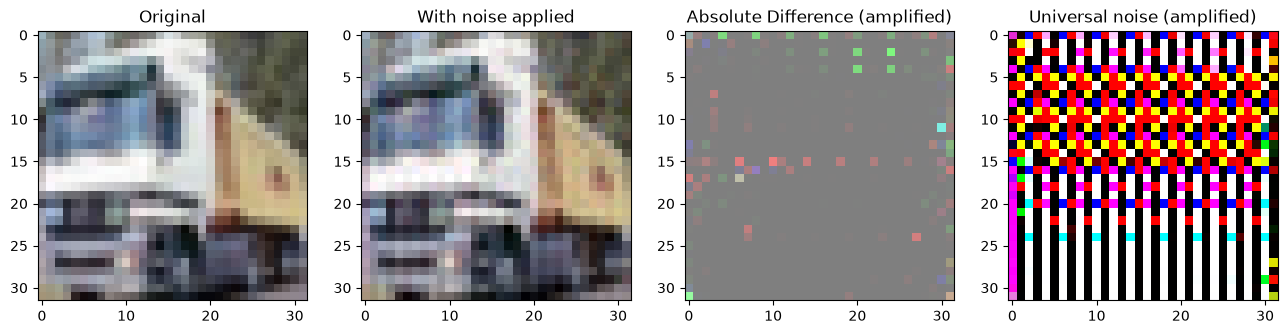

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

generator.load_state_dict(torch.load(model_path, map_location=DEVICE))
noise = generator().detach().cpu().squeeze(0)

img = trucks_tensor[0]
noisy_img = (img + noise).clamp(0, 1)

axes[0].imshow(img.permute(1, 2, 0))
axes[0].set_title('Original')

axes[1].imshow(noisy_img.permute(1, 2, 0))
axes[1].set_title('With noise applied')

axes[2].imshow(1 - np.abs(noisy_img - img).permute(1, 2, 0) / (2 * EPS))   # amplified to be visible
axes[2].set_title('Absolute Difference (amplified)')

axes[3].imshow((noise / (2 * EPS) + 0.5).permute(1, 2, 0))               # same for every truck
axes[3].set_title('Universal noise (amplified)')

plt.show()

# Quick check

- **Max change per pixel**: should be ≤ 6 (out of 255).
- **Trucks classified as deer**: on test trucks, before and after adding the noise. A large increase means
  the noise carries a strong signal towards *deer*, which is what we want for the backdoor.

In [14]:
test_dataset = datasets.CIFAR10("./data/data_cifar10", train=False, download=False, transform=transform)
test_trucks = torch.stack([img for img, label in test_dataset if label == source_index]).to(DEVICE)

with torch.no_grad():
    noise = generator()
    pred_clean = surrogate(normalize_cifar(test_trucks)).argmax(1)
    pred_noisy = surrogate(normalize_cifar((test_trucks + noise).clamp(0, 1))).argmax(1)

print(f"Max change per pixel: {noise.abs().max().item() * 255:.1f} / 255")
print(f"Trucks classified as deer | clean: {(pred_clean == target_index).float().mean():.3f}, "
      f"with noise: {(pred_noisy == target_index).float().mean():.3f}")

Max change per pixel: 6.0 / 255
Trucks classified as deer | clean: 0.002, with noise: 0.096


# Next step: expert model

The saved noise is used by FLIP through the poisoner flag `1xg`. From the repo root:

```bash
python run_experiment.py gan_universal
```

At the end, the expert prints `clean_test_acc` and `poison_test_acc`: compare them with the sinusoidal trigger
(`python run_experiment.py example_attack`).